# Probability of default (PD) for every model

So far each model gave a **score** and we chose a cutoff for F1. A **probability of default** must mean what it says: among applicants given PD = 0.30, about 30% should actually default. This property is called **calibration**.

| Model | What it outputs | Calibrated? |
|---|---|---|
| Logistic regression (no SMOTE) | probability | roughly yes (trained on the real 22% default rate) |
| Anything + SMOTE | probability or score | **no**: learned from a 50/50 world, so PDs are inflated |
| Linear / RBF SVM | distance from the boundary | **not a probability at all** |
| Decision tree | share of defaulters in the leaf | coarse, and over-confident when leaves are small |

**Plan (training set only; the test set stays locked):**
1. Rebuild every model with the hyperparameters chosen earlier, and get **out-of-fold scores** on the same 5 folds.
2. Turn scores into PDs with three methods: **raw** (when the model already gives a probability), **Platt scaling** (sigmoid) and **isotonic regression**.
3. Fit the calibration mapping by **cross-fitting**: the mapping used for fold *k* is learned only from the other 4 folds' out-of-fold scores and labels, so no applicant's own label is used to calibrate their PD.
4. Judge PD quality with **reliability diagrams**, **Brier score**, **log loss** and **expected calibration error**, and check F1 at the best PD cutoff.

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.exceptions import ConvergenceWarning

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.credit import (RANDOM_STATE, DATA, REPORTS, load_train, make_cv, make_pipeline,
                        best_cutoff, fold_metrics)

X_train, y_train = load_train()
cv = make_cv()
BASE_RATE = y_train.mean()
print("X_train:", X_train.shape, f"  actual default rate: {BASE_RATE:.4f}")

X_train: (25927, 11)   actual default rate: 0.2187


## Step 1: The models, with the settings chosen earlier

| Model | Settings | Chosen in |
|---|---|---|
| Logistic regression | defaults | notebook 02, Steps 2–3 |
| Linear soft-margin SVM | C = 3 (no SMOTE), C = 0.1 (+ SMOTE) | notebook 02, Step 5 |
| RBF SVM | C = 100, γ = 0.03 (no SMOTE); C = 30, γ = 0.03 (+ SMOTE) | notebook 02, Step 6c |
| Decision tree (no SMOTE) | read from `reports/decision_tree_choice.json` | notebook 03, Step 3 |
| Random Forest (no SMOTE, 300 trees) | read from `reports/random_forest_choice.json` | notebook 05, Step 3 |

Trees and forests are trained without SMOTE (notebook 02 showed SMOTE does not improve F1 once the cutoff is tuned). Out-of-fold scores are cached in `data/processed/oof_scores.npz`, so re-running this notebook skips the slow SVMs. Delete that file to recompute everything.

In [2]:
def describe(name, p):
    return f"{name}, " + ", ".join(f"{k}={v}" for k, v in p.items())

tree_p = json.loads((REPORTS / "decision_tree_choice.json").read_text())["Tree"]["params"]

# name -> (pipeline, how the model outputs its score)
MODELS = {
    "LogReg (no SMOTE)": (make_pipeline(LogisticRegression(max_iter=1000)), "predict_proba"),
    "LogReg + SMOTE": (make_pipeline(LogisticRegression(max_iter=1000), use_smote=True), "predict_proba"),
    "Linear SVM (no SMOTE), C=3": (make_pipeline(LinearSVC(C=3, loss="hinge", dual=True, max_iter=20000)),
                                   "decision_function"),
    "Linear SVM + SMOTE, C=0.1": (make_pipeline(LinearSVC(C=0.1, loss="hinge", dual=True, max_iter=20000),
                                                use_smote=True), "decision_function"),
    "SVM RBF (no SMOTE), C=100, gamma=0.03": (make_pipeline(SVC(kernel="rbf", C=100, gamma=0.03)),
                                              "decision_function"),
    "SVM RBF + SMOTE, C=30, gamma=0.03": (make_pipeline(SVC(kernel="rbf", C=30, gamma=0.03), use_smote=True),
                                          "decision_function"),
    describe("Tree", tree_p): (make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE, **tree_p)),
                               "predict_proba"),
}

# Random Forest chosen in notebook 05 (skipped if that notebook has not been run yet)
RF_FILE = REPORTS / "random_forest_choice.json"
if RF_FILE.exists():
    rf = json.loads(RF_FILE.read_text())["Random Forest"]
    MODELS[describe("Random Forest", rf["params"])] = (
        make_pipeline(RandomForestClassifier(n_estimators=rf["n_estimators"], random_state=RANDOM_STATE,
                                             n_jobs=-1, **rf["params"])), "predict_proba")
else:
    print("reports/random_forest_choice.json not found: run notebook 05 to include the Random Forest")

CACHE = DATA / "oof_scores.npz"
oof = dict(np.load(CACHE)) if CACHE.exists() else {}
for name, (pipe, method) in MODELS.items():
    if name in oof and len(oof[name]) == len(y_train):
        print(f"{name:<45} cached")
        continue
    start = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        s = cross_val_predict(pipe, X_train, y_train, cv=cv, method=method, n_jobs=5)
    oof[name] = s[:, 1] if method == "predict_proba" else s
    np.savez(CACHE, **oof)
    print(f"{name:<45} {time.time() - start:6.0f}s")

LogReg (no SMOTE)                             cached
LogReg + SMOTE                                cached
Linear SVM (no SMOTE), C=3                    cached
Linear SVM + SMOTE, C=0.1                     cached
SVM RBF (no SMOTE), C=100, gamma=0.03         cached
SVM RBF + SMOTE, C=30, gamma=0.03             cached
Tree, max_depth=10, min_samples_leaf=1, criterion=entropy cached
Random Forest, max_depth=30, min_samples_leaf=1, criterion=gini, max_features=0.5 cached


## Step 2: Calibration methods, applied by cross-fitting

- **Raw:** use `predict_proba` as it is (only for logistic regression and trees).
- **Platt scaling (sigmoid):** fit a one-feature logistic regression $PD = 1/(1 + e^{-(a\,s + b)})$ on the score $s$. It assumes the distortion is S-shaped, and suits SVM scores. (For models that already output a probability, $s$ is its log-odds.)
- **Isotonic regression:** fit the best **non-decreasing step function** from score to PD. It makes no shape assumption, but needs plenty of data (we have about 20,000 rows per fit).

Both mappings are **monotone**: they never change the order of applicants, so ROC-AUC and the best achievable F1 stay (almost) the same. Only the scale changes, so the PD cutoff is re-found on the new scale.

**Cross-fitting.** For each fold *k*, the mapping is fitted on the out-of-fold scores and labels of the other 4 folds and applied to fold *k*. Every applicant gets a calibrated PD whose mapping never saw their own outcome.

**How we judge PDs:**

| Measure | Meaning | Better |
|---|---|---|
| mean PD | should equal the actual default rate (0.219) | close to 0.219 |
| Brier score | mean of (PD − outcome)² | lower |
| log loss | heavily punishes confident mistakes | lower |
| ECE | average gap between predicted PD and actual default rate over 10 equal-size bins | lower |

In [3]:
EPS = 1e-3   # keep PDs inside [0.001, 0.999] so log loss stays finite

def as_logit(score, method):
    if method == "predict_proba":
        p = np.clip(score, EPS, 1 - EPS)
        return np.log(p / (1 - p))
    return score

def crossfit_calibrate(score, how):
    pd_ = np.empty(len(score))
    for tr, va in cv.split(X_train, y_train):
        if how == "Platt (sigmoid)":
            m = LogisticRegression(C=1e6).fit(score[tr].reshape(-1, 1), y_train.iloc[tr])
            pd_[va] = m.predict_proba(score[va].reshape(-1, 1))[:, 1]
        else:
            m = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(score[tr], y_train.iloc[tr])
            pd_[va] = m.predict(score[va])
    return np.clip(pd_, EPS, 1 - EPS)

def ece(pd_, y, bins=10):
    edges = np.quantile(pd_, np.linspace(0, 1, bins + 1))
    idx = np.clip(np.searchsorted(edges, pd_, side="right") - 1, 0, bins - 1)
    return sum(abs(pd_[idx == b].mean() - y[idx == b].mean()) * (idx == b).mean()
               for b in range(bins) if (idx == b).any())

pds, rows = {}, []
y = y_train.to_numpy()
for name, (_, method) in MODELS.items():
    s = oof[name]
    versions = {}
    if method == "predict_proba":
        versions["raw"] = np.clip(s, EPS, 1 - EPS)
    versions["Platt (sigmoid)"] = crossfit_calibrate(as_logit(s, method), "Platt (sigmoid)")
    versions["isotonic"] = crossfit_calibrate(s, "isotonic")
    for how, p in versions.items():
        pds[(name, how)] = p
        cut = best_cutoff(p, y_train)
        fm = fold_metrics(p, y_train, cut, X_train, cv)
        rows.append({"model": name, "PD method": how, "mean PD": p.mean(),
                     "Brier": brier_score_loss(y, p), "log loss": log_loss(y, p), "ECE": ece(p, y),
                     "ROC-AUC": roc_auc_score(y, p), "best PD cutoff": cut, "F1 @ best": fm.loc["mean", "f1"]})

pd_table = pd.DataFrame(rows).set_index(["model", "PD method"])
print(f"actual default rate = {BASE_RATE:.4f}\n")
display(pd_table.round(4))

actual default rate = 0.2187



mean PD  \
model                                              PD method                  
LogReg (no SMOTE)                                  raw               0.2188   
                                                   Platt (sigmoid)   0.2187   
                                                   isotonic          0.2187   
LogReg + SMOTE                                     raw               0.3770   
                                                   Platt (sigmoid)   0.2187   
                                                   isotonic          0.2187   
Linear SVM (no SMOTE), C=3                         Platt (sigmoid)   0.2187   
                                                   isotonic          0.2187   
Linear SVM + SMOTE, C=0.1                          Platt (sigmoid)   0.2187   
                                                   isotonic          0.2187   
SVM RBF (no SMOTE), C=100, gamma=0.03              Platt (sigmoid)   0.2186   
                                                   isotonic          0.2188   
SVM RBF + SMOTE, C=30, gamma=0.03                  Platt (sigmoid)   0.2186   
                                                   isotonic          0.2186   
Tree, max_depth=10, min_samples_leaf=1, criteri... raw               0.2178   
                                                   Platt (sigmoid)   0.2187   
                                                   isotonic          0.2192   
Random Forest, max_depth=30, min_samples_leaf=1... raw               0.2267   
                                                   Platt (sigmoid)   0.2187   
                                                   isotonic          0.2186   

                                                                     Brier  \
model                                              PD method                 
LogReg (no SMOTE)                                  raw              0.1021   
                                                   Platt (sigmoid)  0.1021   
                                                   isotonic         0.1015   
LogReg + SMOTE                                     raw              0.1379   
                                                   Platt (sigmoid)  0.1033   
                                                   isotonic         0.1028   
Linear SVM (no SMOTE), C=3                         Platt (sigmoid)  0.1024   
                                                   isotonic         0.1014   
Linear SVM + SMOTE, C=0.1                          Platt (sigmoid)  0.1043   
                                                   isotonic         0.1034   
SVM RBF (no SMOTE), C=100, gamma=0.03              Platt (sigmoid)  0.0692   
                                                   isotonic         0.0690   
SVM RBF + SMOTE, C=30, gamma=0.03                  Platt (sigmoid)  0.0735   
                                                   isotonic         0.0730   
Tree, max_depth=10, min_samples_leaf=1, criteri... raw              0.0623   
                                                   Platt (sigmoid)  0.0620   
                                                   isotonic         0.0619   
Random Forest, max_depth=30, min_samples_leaf=1... raw              0.0562   
                                                   Platt (sigmoid)  0.0559   
                                                   isotonic         0.0556   

                                                                    log loss  \
model                                              PD method                   
LogReg (no SMOTE)                                  raw                0.3402   
                                                   Platt (sigmoid)    0.3404   
                                                   isotonic           0.3381   
LogReg + SMOTE                                     raw                0.4357   
                                                   Platt (sigmoid)    0.3418   
                                                   i

## Step 3: Best PD version per model

For each model, keep the version with the **lowest Brier score** (the most accurate probabilities).

,PD method,mean PD,Brier,log loss,ECE,ROC-AUC,best PD cutoff,F1 @ best
model,,,,,,,,
"Random Forest, max_depth=30, min_samples_leaf=1, criterion=gini, max_features=0.5",isotonic,0.2186,0.0556,0.2019,0.0017,0.9333,0.3784,0.8291
"Tree, max_depth=10, min_samples_leaf=1, criterion=entropy",isotonic,0.2192,0.0619,0.2312,0.0026,0.9053,0.3016,0.8113
"SVM RBF (no SMOTE), C=100, gamma=0.03",isotonic,0.2188,0.0690,0.2488,0.0029,0.9047,0.3987,0.7841
"SVM RBF + SMOTE, C=30, gamma=0.03",isotonic,0.2186,0.0730,0.2584,0.0021,0.9064,0.3750,0.7723
"Linear SVM (no SMOTE), C=3",isotonic,0.2187,0.1014,0.3389,0.0026,0.8640,0.3418,0.6825
LogReg (no SMOTE),isotonic,0.2187,0.1015,0.3381,0.0035,0.8673,0.3505,0.6755
LogReg + SMOTE,isotonic,0.2187,0.1028,0.3407,0.0029,0.8686,0.3803,0.6742
"Linear SVM + SMOTE, C=0.1",isotonic,0.2187,0.1034,0.3428,0.0045,0.8649,0.3231,0.6796


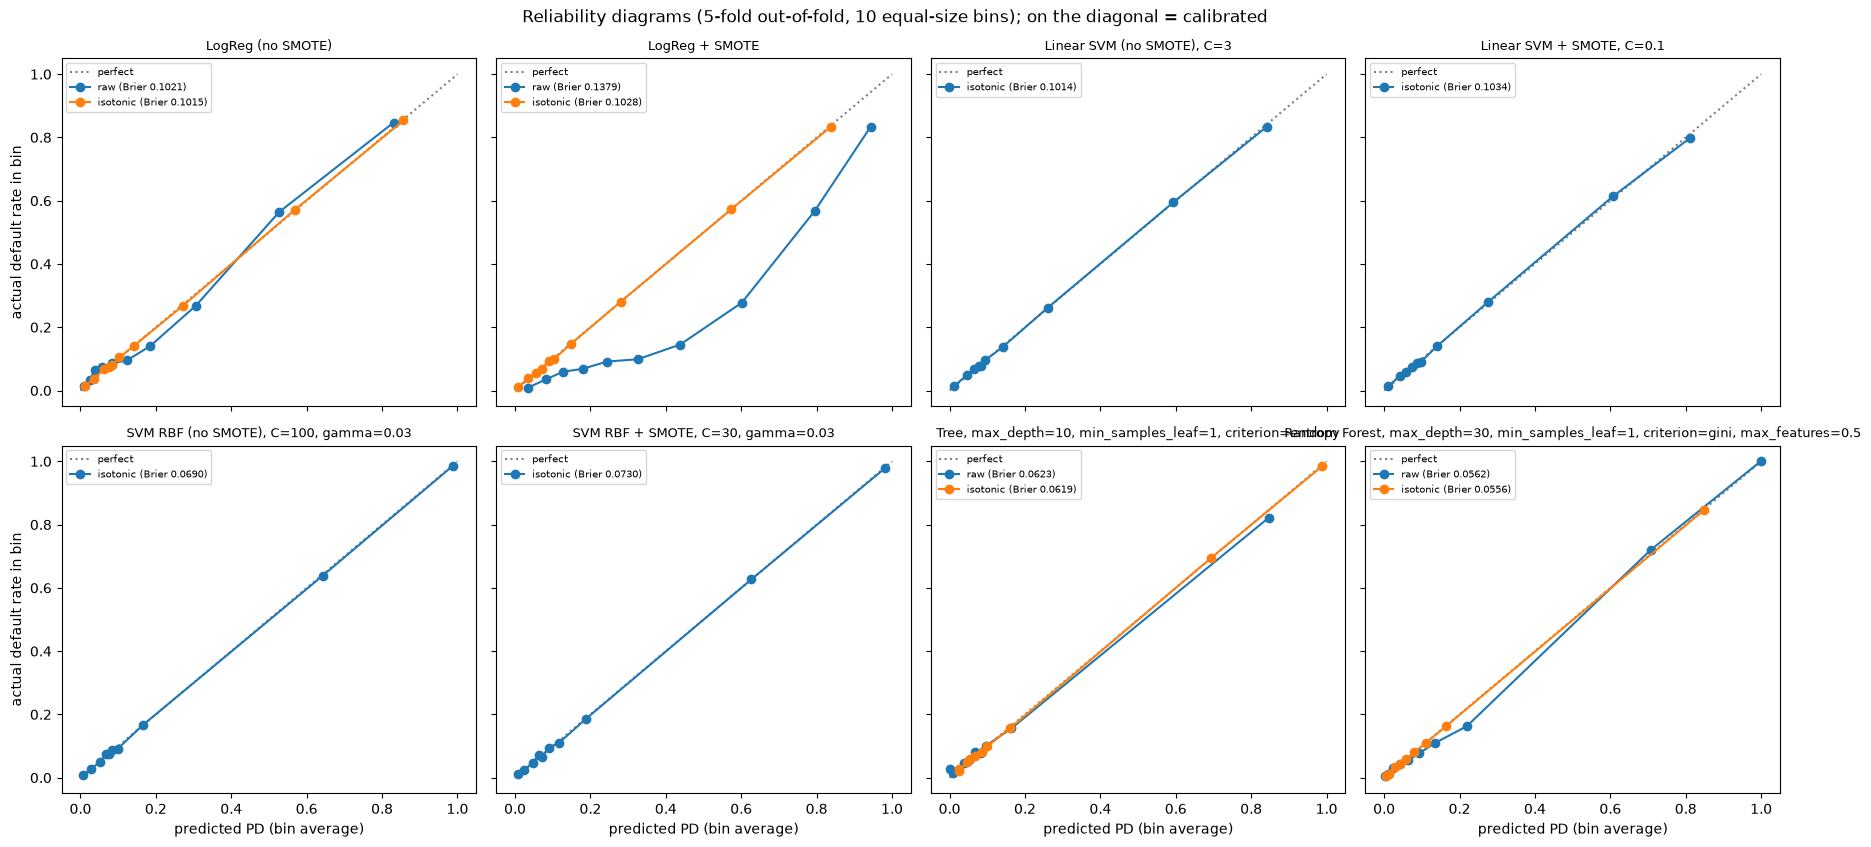

In [4]:
best_how = pd_table["Brier"].groupby(level="model").idxmin()
pd_best = pd_table.loc[best_how.values].reset_index(level="PD method").sort_values("Brier")
display(pd_best.round(4))

# Reliability diagrams: raw (if any) vs the chosen calibration, for every model
names = list(MODELS)
n_rows = int(np.ceil(len(names) / 4))
fig, axes = plt.subplots(n_rows, 4, figsize=(18, 4.3 * n_rows), sharex=True, sharey=True)
for ax in axes.ravel()[len(names):]:
    ax.set_visible(False)
for ax, name in zip(axes.ravel(), names):
    ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="perfect")
    shown = ["raw"] if (name, "raw") in pds else []
    shown.append(pd_best.loc[name, "PD method"])
    for how in dict.fromkeys(shown):
        frac, mean_pred = calibration_curve(y, pds[(name, how)], n_bins=10, strategy="quantile")
        ax.plot(mean_pred, frac, marker="o", label=f"{how} (Brier {pd_table.loc[(name, how), 'Brier']:.4f})")
    ax.set_title(name, fontsize=9)
    ax.legend(fontsize=7, loc="upper left")
for ax in axes[-1]:
    ax.set_xlabel("predicted PD (bin average)")
for ax in axes[:, 0]:
    ax.set_ylabel("actual default rate in bin")
fig.suptitle("Reliability diagrams (5-fold out-of-fold, 10 equal-size bins); on the diagonal = calibrated")
plt.tight_layout(); plt.show()

## Step 4: What the PDs look like

For the best model (lowest Brier score): the PD distribution for applicants who actually repaid vs. defaulted, and a few example applicants. Every applicant gets a PD; the decision rule (*default if PD ≥ cutoff*) is applied on top.

best PD model: Random Forest, max_depth=30, min_samples_leaf=1, criterion=gini, max_features=0.5  [isotonic],  F1-best PD cutoff = 0.378


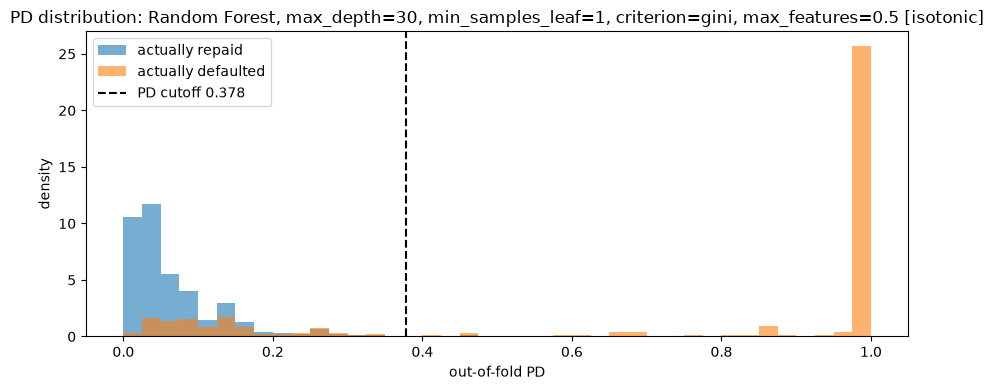

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,PD,decision,actual outcome
16948,28,61000,RENT,12.0,HOMEIMPROVEMENT,C,15000,13.99,0.25,N,7,0.088,low risk (approve),repaid
2312,39,108000,MORTGAGE,3.0,HOMEIMPROVEMENT,A,12000,6.99,0.11,N,13,0.002,low risk (approve),defaulted
20021,33,84996,RENT,2.0,EDUCATION,A,4000,8.59,0.05,N,6,0.009,low risk (approve),repaid
2176,22,70550,RENT,6.0,MEDICAL,D,15000,16.77,0.18,Y,2,0.999,high risk (decline),defaulted
18189,27,39996,RENT,7.0,DEBTCONSOLIDATION,D,2500,15.65,0.06,N,8,0.999,high risk (decline),defaulted
22274,21,44000,RENT,0.0,PERSONAL,D,5500,15.28,0.13,N,3,0.999,high risk (decline),defaulted


In [5]:
top = pd_best.index[0]
top_how = pd_best.loc[top, "PD method"]
top_pd = pds[(top, top_how)]
top_cut = pd_best.loc[top, "best PD cutoff"]
print(f"best PD model: {top}  [{top_how}],  F1-best PD cutoff = {top_cut:.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1, 41)
ax.hist(top_pd[y == 0], bins=bins, alpha=0.6, label="actually repaid", density=True)
ax.hist(top_pd[y == 1], bins=bins, alpha=0.6, label="actually defaulted", density=True)
ax.axvline(top_cut, color="black", linestyle="--", label=f"PD cutoff {top_cut:.3f}")
ax.set_xlabel("out-of-fold PD"); ax.set_ylabel("density"); ax.legend()
ax.set_title(f"PD distribution: {top} [{top_how}]")
plt.tight_layout(); plt.show()

# 3 random applicants below the cutoff and 3 above it, so both decisions are visible
rng = np.random.default_rng(RANDOM_STATE)
pick = np.r_[rng.choice(np.where(top_pd < top_cut)[0], 3, replace=False),
             rng.choice(np.where(top_pd >= top_cut)[0], 3, replace=False)]
examples = X_train.iloc[pick].copy()
examples["PD"] = top_pd[pick].round(3)
examples["decision"] = np.where(examples["PD"] >= top_cut, "high risk (decline)", "low risk (approve)")
examples["actual outcome"] = y_train.iloc[pick].map({0: "repaid", 1: "defaulted"}).values
display(examples)

## Step 5: Save the out-of-fold PDs

The best-calibrated out-of-fold PD of every model is saved (one column per model, one row per training applicant, same order as `train.csv`). These are what a later interest-rate model can use as a feature (*risk-based pricing*) without leakage, because each PD came from a model and a calibration mapping that never saw that applicant's outcome.

For the final model, the same recipe is applied once at the end: fit the model on the full training set, fit the calibration mapping on all its out-of-fold scores, then score the test set.

In [6]:
oof_pd = pd.DataFrame({name: pds[(name, pd_best.loc[name, "PD method"])] for name in MODELS})
oof_pd.to_csv(DATA / "oof_pd.csv", index=False)
pd_best.round(4).to_csv(REPORTS / "pd_summary.csv")
print("saved data/processed/oof_pd.csv", oof_pd.shape, "and reports/pd_summary.csv")
display(oof_pd.describe().T[["mean", "min", "25%", "50%", "75%", "max"]].round(3))

saved data/processed/oof_pd.csv (25927, 8) and reports/pd_summary.csv


,mean,min,25%,50%,75%,max
LogReg (no SMOTE),0.219,0.001,0.065,0.086,0.276,0.999
LogReg + SMOTE,0.219,0.001,0.056,0.092,0.262,0.999
"Linear SVM (no SMOTE), C=3",0.219,0.001,0.062,0.084,0.250,0.999
"Linear SVM + SMOTE, C=0.1",0.219,0.001,0.060,0.090,0.254,0.999
"SVM RBF (no SMOTE), C=100, gamma=0.03",0.219,0.001,0.051,0.077,0.154,0.999
"SVM RBF + SMOTE, C=30, gamma=0.03",0.219,0.001,0.040,0.076,0.190,0.999
"Tree, max_depth=10, min_samples_leaf=1, criterion=entropy",0.219,0.023,0.051,0.081,0.159,0.989
"Random Forest, max_depth=30, min_samples_leaf=1, criterion=gini, max_features=0.5",0.219,0.002,0.030,0.066,0.151,0.999
